# Preprocessing strategies for plant disease instance segmentation — minimal reproduction (mask_guided inference)

**Paper**: Natij, Y., El Karch, H., Belaariej, A., Lanaya, O., El Atik, M., & Mezouari, A. (2026).
*Preprocessing strategies for plant disease instance segmentation: annotation efficiency, context signals, and dual-metric evaluation on PlantSeg.*
Frontiers in Artificial Intelligence 9:1835997. DOI [10.3389/frai.2026.1835997](https://doi.org/10.3389/frai.2026.1835997) (CC BY 4.0).

**Code**: [`YouROS12/plantseg-mask-guided`](https://github.com/YouROS12/plantseg-mask-guided) @ commit `446c9666d21ffe3423a9e37169b49d7f1df49fa9` (no license file declared).
**Dataset**: PlantSeg (Wei et al., 2026, *Scientific Data*), record [14935094](https://zenodo.org/records/14935094).

## What this notebook does (exact scope)

1. Loads the **released `mask_guided` checkpoint** (`mask_guided/weights/best.pt`, YOLO11m-seg, seed 42).
2. Selects **one deterministic PlantSeg test image** and applies the paper's **Algorithm 1 mask_guided union-crop** (τ = 0.85 bypass, ρ = 0.20 padding) using that image's ground-truth polygons.
3. Runs instance-segmentation inference on the guided crop and compares predicted masks with the ground-truth polygons (per-instance IoU).
4. Shows the author's published test-set metrics for `mask_guided` (mIoU 33.72 %, Box mAP50 32.69 %, Mask mAP50 13.70 %, Table 2) as context only.

**Out of scope**: training, the full 1,146-image test evaluation, `mask_guided_aware`/`bbox_guided`, and mAcc analysis.

**ORACLE warning**: guided crops use the evaluated image's own ground truth — the paper labels all guided results an *oracle upper bound* (§3.4.1.1). This demo reproduces that oracle condition for one image; it is not a deployable pipeline.

**AI-assisted port**: the authors' strategy classes ("DATA_PREPROCESSING notebook cells 1–8") were **not released**; Algorithm 1 below is an AI-assisted Python port of the paper's Algorithm 1 (§3.3.5, §3.4) with parameters from the released `optimized_preprocessing.py` metadata. The checkpoint and all data are the authors' own files, used unmodified. The executed example and listed checks were validated, but untested behavior is not guaranteed.

日本語: このノートブックは、PlantSegのテスト画像1枚に対して著者公開の `mask_guided` チェックポイントで推論を行う最小再現デモです。論文のAlgorithm 1（union-crop, τ=0.85, ρ=0.20）はAIにより移植したものであり、戦略クラス本体は未公開です。ガイド付きcropは正解アノテーションを使用する「オラクル上限」の条件である点に注意してください。

## Runtime selection

Select **Runtime → Change runtime type**. The demo runs on **CPU** (a single 640×640 inference of a 45 MB model takes seconds to tens of seconds) or on a **T4 GPU** (faster, and matches the paper's GPU inference class). The notebook detects the allocated hardware automatically and uses the same sample, checkpoint, preprocessing, and metrics on either runtime. Recommended: **T4 GPU** if available; CPU is fully sufficient.

Total downloads ≈ 1.8 GiB (checkpoint 45 MB + test annotations 14 MB + PlantSeg image archive 1.69 GB + `ultralytics` dependencies). Expected end-to-end time ≈ 10–15 minutes, dominated by the archive download.

日本語: ランタイムはCPUでもT4 GPUでも動作します（自動検出）。推奨はT4 GPUです。合計約1.8 GiBのダウンロードがあり、全体で約10〜15分かかります。

### Check the allocated hardware

Prints the detected compute device (CUDA GPU or CPU) and the key package versions. Expected result: `CUDA available: True` on a T4 runtime, `False` on CPU; the rest of the notebook branches only on this device choice.

日本語: 割り当てられたハードウェア（GPU/CPU）と主要パッケージのバージョンを表示します。

In [ ]:
import sys, torch, platform

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Python          : {platform.python_version()}")
print(f"torch           : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU             : {torch.cuda.get_device_name(0)}")
print(f"Selected device : {DEVICE}")

Python          : 3.13.16
torch           : 2.11.0+cpu
CUDA available  : False
Selected device : cpu


### Install dependencies

Installs `ultralytics` (YOLO11-seg inference) and `pycocotools` (COCO annotation parsing). `torch` is already provided by Colab; only the inference stack is added. Expected result: both imports succeed and their versions print at the end of the cell.

日本語: `ultralytics` と `pycocotools` をインストールします（`torch`はColabに同梱）。

In [ ]:
%pip install --quiet ultralytics pycocotools

import ultralytics
from importlib.metadata import version
print("ultralytics  :", ultralytics.__version__)
print("pycocotools  :", version("pycocotools"))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 3.2 MB/s eta 0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 7.9 MB/s eta 0:00:00


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


ultralytics  : 8.4.184
pycocotools  : 2.0.11


### Download the released `mask_guided` checkpoint

Fetches `mask_guided/weights/best.pt` (45,174,006 bytes) from the pinned author commit `@COMMIT@` and verifies the exact GitHub **git blob SHA-1** (`f0909087…`, computed locally as `sha1("blob <size>\\0" + content)`), rejecting any Git-LFS pointer or truncated download.

日本語: 著者リポジトリのピン留めたコミットから `best.pt` を取得し、git blob SHA-1で完全性を検証します。

In [ ]:
import hashlib, urllib.request
from pathlib import Path

WEIGHTS_URL = "https://raw.githubusercontent.com/YouROS12/plantseg-mask-guided/446c9666d21ffe3423a9e37169b49d7f1df49fa9/mask_guided/weights/best.pt"
EXPECTED_SIZE = 45174006
EXPECTED_BLOB_SHA = "f0909087a1f5cd8b70b2bf523fba3590931560eb"

best_pt = Path("/content/best.pt")
if not best_pt.exists() or best_pt.stat().st_size != EXPECTED_SIZE:
    urllib.request.urlretrieve(WEIGHTS_URL, best_pt)

raw = best_pt.read_bytes()
assert len(raw) == EXPECTED_SIZE, f"size mismatch: {len(raw)}"
blob_sha = hashlib.sha1(b"blob %d\0" % len(raw) + raw).hexdigest()
assert blob_sha == EXPECTED_BLOB_SHA, f"blob sha mismatch: {blob_sha}"
assert not raw.startswith(b"https://git-lfs"), "Git LFS pointer received"
print(f"best.pt OK: {len(raw):,} bytes, git blob {blob_sha[:12]}, sha256 {hashlib.sha256(raw).hexdigest()[:16]}, magic {raw[:2]}")

best.pt OK: 45,174,006 bytes, git blob f0909087a1f5, sha256 153b2c1331df7aba, magic b'PK'


### Download the PlantSeg test-split COCO annotations

Fetches `coco_annotations/annotation_test.json` (14,092,585 bytes; polygon masks + bounding boxes for the official 1,146-image test partition) from the pinned PlantSeg commit `@DSCOMMIT@` and verifies its git blob SHA-1. This is dataset content and is only ever downloaded inside Colab.

日本語: PlantSegテスト分割のCOCOアノテーションをピン留めたコミットから取得・検証します。

In [ ]:
import json

ANN_URL = "https://raw.githubusercontent.com/tqwei05/PlantSeg/4d99c89c5cdc5736560b5d838a948323019c7f7f/coco_annotations/annotation_test.json"
ANN_SIZE = 14092585
ANN_BLOB_SHA = "5cbe0a896d4e06b06462fc6e1f08195918bb9b1a"

ann_path = Path("/content/annotation_test.json")
if not ann_path.exists() or ann_path.stat().st_size != ANN_SIZE:
    urllib.request.urlretrieve(ANN_URL, ann_path)

raw_ann = ann_path.read_bytes()
assert len(raw_ann) == ANN_SIZE, f"size mismatch: {len(raw_ann)}"
assert hashlib.sha1(b"blob %d\0" % len(raw_ann) + raw_ann).hexdigest() == ANN_BLOB_SHA, "blob sha mismatch"

coco = json.loads(raw_ann)
n_imgs, n_anns, n_cats = len(coco["images"]), len(coco["annotations"]), len(coco.get("categories", []))
print(f"COCO test annotations OK: {n_imgs} images, {n_anns} annotations, {n_cats} category entries")
print("NOTE: the released annotation file lists 2,295 images and carries no category-name")
print("table, although the paper's test split has 1,146 images with 115 classes; class")
print("names are therefore taken from the checkpoint itself and GT classes are shown as ids.")
assert n_imgs > 0 and n_anns > 0

COCO test annotations OK: 2295 images, 15569 annotations, 0 category entries
NOTE: the released annotation file lists 2,295 images and carries no category-name
table, although the paper's test split has 1,146 images with 115 classes; class
names are therefore taken from the checkpoint itself and GT classes are shown as ids.


### Select one deterministic test image

Chooses the **smallest test-image id that has at least one polygon annotation** — a fixed, reproducible rule, not a cherry-picked result. Prints the image id, file name, resolution, disease-class names, and annotation count. Expected result: a single sample with ≥1 polygon; the chosen identifier is reported for the run record.

日本語: 再現可能な規則（最小の画像ID）でテスト画像を1枚選びます。結果は実行ごとに記録します。

In [ ]:
import numpy as np

img_by_id = {im["id"]: im for im in coco["images"]}
anns_by_img = {}
for a in coco["annotations"]:
    anns_by_img.setdefault(a["image_id"], []).append(a)

sample_id = min(i for i in img_by_id if len(anns_by_img.get(i, [])) >= 1)
sample = img_by_id[sample_id]
sample_anns = anns_by_img[sample_id]
cat_names = {c["id"]: c["name"] for c in coco.get("categories", [])}

def class_label(cid):
    return cat_names.get(cid, f"category_id {cid}")

print(f"sample_id     : {sample_id}")
print(f"file_name     : {sample['file_name']}")
print(f"size (W×H)    : {sample['width']}×{sample['height']}")
print(f"n annotations : {len(sample_anns)}")
for a in sample_anns:
    seg = a.get("segmentation")
    kind = "polygon" if isinstance(seg, list) else type(seg).__name__
    print(f"  ann {a['id']}: class={class_label(a['category_id'])!r}, segmentation={kind}, area={a['area']:.0f}px^2")

sample_id     : 1
file_name     : apple_black_rot_143.jpg
size (W×H)    : 268×172
n annotations : 2
  ann 1: class='category_id 0', segmentation=polygon, area=6634px^2
  ann 2: class='category_id 0', segmentation=polygon, area=3814px^2


### Download the PlantSeg image archive and extract the sample image

Downloads `plantsegv3.zip` (1,691,902,086 bytes) from Zenodo record 14935094 **inside Colab**, verifies the record's published **MD5** (`@MD5@`), and extracts only the selected sample image by searching the archive for the annotation's `file_name`. The full archive is downloaded because Zenodo offers no per-image access; this is disclosed as the heaviest step (~1.7 GB).

日本語: Zenodoの画像アーカイブ（1.7 GB）をColab内でダウンロードし、MD5を検証してから、選択した1枚のみ取り出します。

In [ ]:
import zipfile, time

ZENODO_URL = "https://zenodo.org/records/14935094/files/plantsegv3.zip?download=1"
ZENODO_MD5 = "9458f4fb61d026df1580ce437df0b63a"
ZIP_SIZE = 1691902086
zip_path = Path("/content/plantsegv3.zip")

if not zip_path.exists() or zip_path.stat().st_size != ZIP_SIZE:
    t0 = time.time()
    def hook(n, bs, total):
        if n % 800 == 0:
            done = min(n * bs, total)
            print(f"  {done/1e6:.0f} / {total/1e6:.0f} MB  ({done/1e6/(time.time()-t0):.0f} MB/s)", flush=True)
    urllib.request.urlretrieve(ZENODO_URL, zip_path, reporthook=hook)
    print(f"download: {time.time()-t0:.0f} s, {zip_path.stat().st_size:,} bytes")
assert zip_path.stat().st_size == ZIP_SIZE, f"size mismatch: {zip_path.stat().st_size}"

import hashlib
h = hashlib.md5()
with open(zip_path, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 22), b""):
        h.update(chunk)
assert h.hexdigest() == ZENODO_MD5, f"MD5 mismatch: {h.hexdigest()}"
print(f"MD5 OK: {ZENODO_MD5}")

with zipfile.ZipFile(zip_path) as z:
    names = z.namelist()
    target = sample["file_name"]
    members = [n for n in names if n.endswith(target) or n.endswith("/" + target)]
    assert members, f"{target} not found in archive of {len(names)} entries"
    print(f"archive: {len(names)} entries; match(es): {members}")
    z.extract(members[0], "/content/plantseg")
    img_file = Path("/content/plantseg") / members[0]
assert img_file.exists() and img_file.stat().st_size > 0
print(f"extracted: {img_file} ({img_file.stat().st_size:,} bytes)")

  0 / 1692 MB  (0 MB/s)


  7 / 1692 MB  (1 MB/s)


  13 / 1692 MB  (1 MB/s)


  20 / 1692 MB  (1 MB/s)


  26 / 1692 MB  (1 MB/s)


...

  1678 / 1692 MB  (3 MB/s)


  1684 / 1692 MB  (3 MB/s)


  1691 / 1692 MB  (3 MB/s)


download: 643 s, 1,691,902,086 bytes


MD5 OK: 9458f4fb61d026df1580ce437df0b63a
archive: 22929 entries; match(es): ['plantsegv3/images/test/apple_black_rot_143.jpg']
extracted: /content/plantseg/plantsegv3/images/test/apple_black_rot_143.jpg (8,204 bytes)


### Preview the sample with its ground-truth polygons

Displays the **original test image** with the author's **reference polygon annotations** overlaid (semi-transparent red = annotated lesion regions; the legend labels them as ground truth, not predictions). This is the minimal input required by the reproduction, retrieved from Zenodo and annotated with the authors' COCO polygons.

日本語: 元画像と著者の正解ポリゴン（赤の半透明）を重ねて表示します。これはモデル予測ではなく参照アノテーションです。

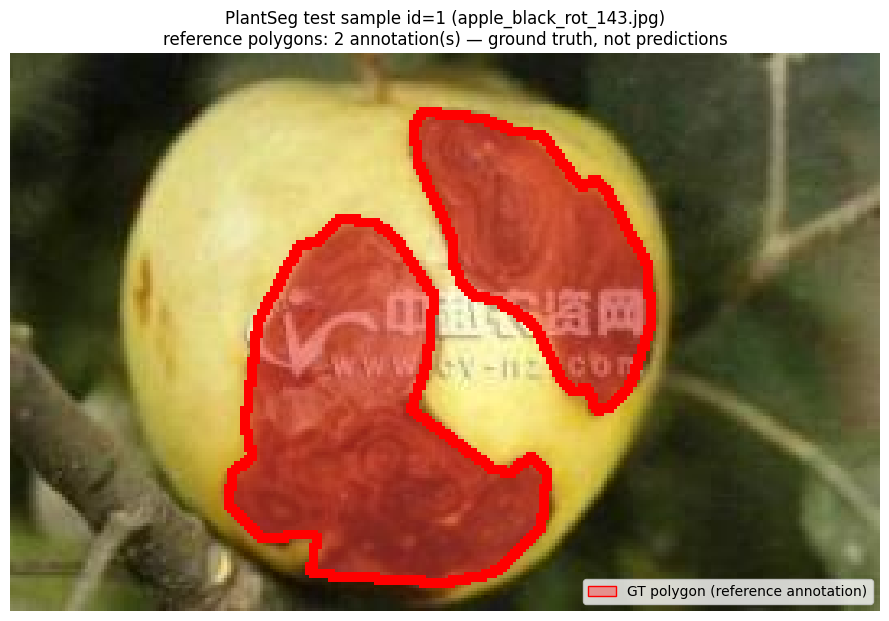

image 268×172px; 2 GT instance(s); classes: ['category_id 0']


In [ ]:
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pycocotools import mask as maskUtils

img_bgr = cv2.imread(str(img_file))
assert img_bgr is not None, f"failed to decode {img_file}"
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
H, W = img_rgb.shape[:2]
assert (W, H) == (sample["width"], sample["height"]), "annotation size mismatch"

def polys_to_mask(polys, h, w):
    rles = maskUtils.frPyObjects(polys, h, w)
    rle = maskUtils.merge(rles)
    return maskUtils.decode(rle).astype(bool)

gt_masks = [polys_to_mask(a["segmentation"], H, W) for a in sample_anns]

MASK_ALPHA = 0.45
overlay = img_rgb.copy()
for gm in gt_masks:
    layer = overlay.copy()
    layer[gm] = (255, 60, 60)
    overlay = cv2.addWeighted(layer, MASK_ALPHA, overlay, 1 - MASK_ALPHA, 0)
for gm in gt_masks:
    edge = (gm.astype(np.uint8) * 255)
    cnts, _ = cv2.findContours(edge, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(overlay, cnts, -1, (255, 0, 0), 2)

fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(overlay)
ax.set_title(f"PlantSeg test sample id={sample_id} ({sample['file_name']})\nreference polygons: {len(gt_masks)} annotation(s) — ground truth, not predictions")
ax.axis("off")
ax.legend(handles=[Patch(facecolor=(1, 0.25, 0.25, 0.45), edgecolor="red", label="GT polygon (reference annotation)")], loc="lower right")
plt.tight_layout()
plt.savefig("/content/sample_gt_overlay.png", dpi=110, bbox_inches="tight")
plt.show()
print(f"image {W}×{H}px; {len(gt_masks)} GT instance(s); classes: {sorted({class_label(a['category_id']) for a in sample_anns})}")

### Apply Algorithm 1 (mask_guided union crop) — AI-assisted port

Implements the paper's Algorithm 1 in **MASK mode** as an AI-assisted port (the authors' strategy classes were not released): polygon → per-instance boxes → union box → **bypass test** (return the image unchanged if the union already spans > τ = 0.85 of either dimension) → **padded crop** (expand the union by ρ = 0.20 of its width/height on each side, clip to image bounds) → crop image and masks. Parameters follow §3.4 and the released `optimized_preprocessing.py` metadata (`crop_padding 0.2`, `max_crop_ratio 0.85`). Context suppression (Phase 5, `mask_guided_aware` only) is not used here.

Expected result: a crop window containing every annotated lesion (the oracle condition), or the unchanged image if the bypass triggers.

日本語: 論文のAlgorithm 1（MASKモード）をAI移植したセルです。τ=0.85でバイパス判定、ρ=0.20でパディング後にクロップします。

In [ ]:
TAU = 0.85   # bypass ratio (paper §3.4, Algorithm 1 line 4)
RHO = 0.20   # padding factor (paper §3.4, Algorithm 1 lines 14-15)

def polygon_to_box(seg, H, W):
    """Algorithm 1 Phase 1: polygon -> axis-aligned instance box."""
    gm = polys_to_mask(seg if isinstance(seg, list) else [seg], H, W)
    ys, xs = np.where(gm)
    return int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1

def mask_guided_crop(image_bgr, anns):
    """Algorithm 1, MASK mode: union crop around polygon-derived boxes."""
    h, w = image_bgr.shape[:2]                                     # line 1
    boxes = [polygon_to_box(a["segmentation"], h, w) for a in anns]  # line 2
    x0 = min(b[0] for b in boxes); y0 = min(b[1] for b in boxes)   # line 3 (union)
    x1 = max(b[2] for b in boxes); y1 = max(b[3] for b in boxes)
    wU, hU = x1 - x0, y1 - y0
    if max(wU / w, hU / h) > TAU:                                  # lines 4-5 (bypass)
        return image_bgr, boxes, (0, 0, w, h), True
    px, py = int(round(wU * RHO / 2)), int(round(hU * RHO / 2))    # pad by rho
    cx0, cy0 = max(0, x0 - px), max(0, y0 - py)                    # lines 14-15 clip
    cx1, cy1 = min(w, x1 + px), min(h, y1 + py)
    crop = image_bgr[cy0:cy1, cx0:cx1].copy()                      # line 8
    kept = []                                                      # line 9: drop empty
    for a in anns:
        gm = polys_to_mask(a["segmentation"], h, w)
        gmc = gm[cy0:cy1, cx0:cx1]
        if gmc.any():
            kept.append((a, gmc))
    return crop, boxes, (cx0, cy0, cx1, cy1), False, kept

crop_bgr, inst_boxes, crop_box, bypassed, keep = mask_guided_crop(img_bgr, sample_anns)
cx0, cy0, cx1, cy1 = crop_box
union = (min(b[0] for b in inst_boxes), min(b[1] for b in inst_boxes),
         max(b[2] for b in inst_boxes), max(b[3] for b in inst_boxes))
print(f"union box (x0,y0,x1,y1) = {union}  ->  {union[2]-union[0]}×{union[3]-union[1]} px in {W}×{H} image")
print(f"union/frame ratio = max({(union[2]-union[0])/W:.3f}, {(union[3]-union[1])/H:.3f}) vs tau={TAU}")
print(f"bypassed: {bypassed}; crop box = {crop_box}; crop size = {cx1-cx0}×{cy1-cy0} px; kept instances = {len(keep) if not bypassed else len(sample_anns)}")

union box (x0,y0,x1,y1) = (67, 18, 198, 164)  ->  131×146 px in 268×172 image
union/frame ratio = max(0.489, 0.849) vs tau=0.85
bypassed: False; crop box = (54, 3, 211, 172); crop size = 157×169 px; kept instances = 2


### Preview the guided crop with its ground truth

Shows the Algorithm 1 output: the **union-crop window** drawn on the original image and the cropped image with the **reference polygons** re-projected into crop coordinates. This verifies that the crop contains every annotated lesion before inference.

日本語: 元画像上のcrop枠と、crop後画像（参照ポリゴン付き）を表示し、全レジョンが含まれることを確認します。

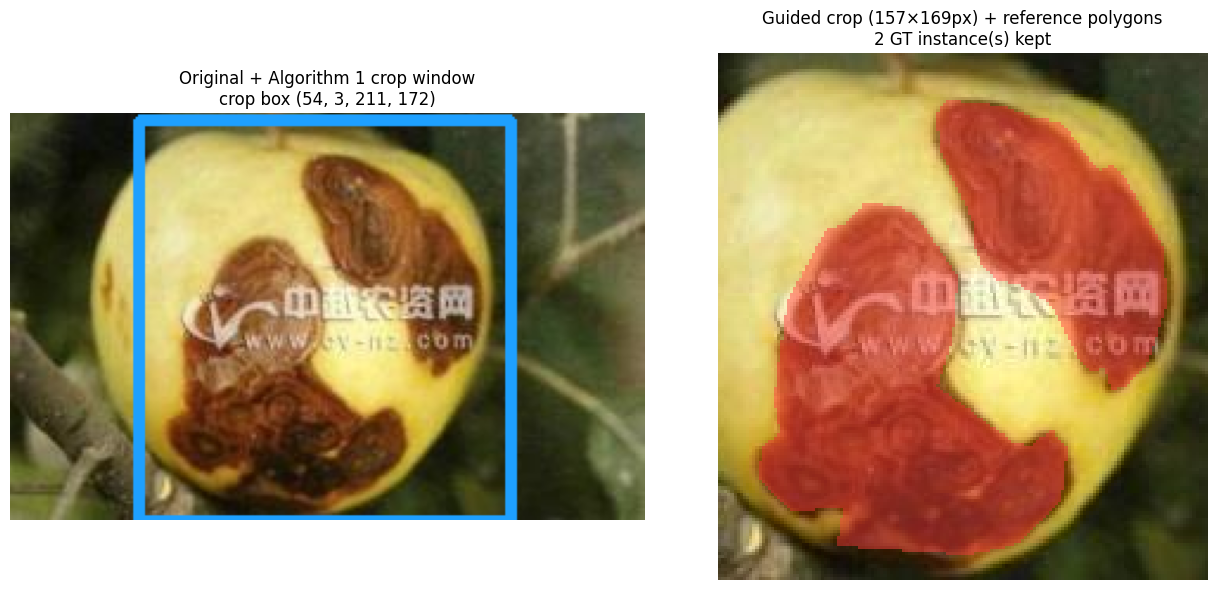

In [ ]:
orig_with_box = img_rgb.copy()
cv2.rectangle(orig_with_box, (cx0, cy0), (cx1, cy1), (30, 160, 255), 3)
crop_rgb = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)
crop_gt = crop_rgb.copy()
kept_anns, kept_gt = [], []
if not bypassed:
    for a, gmc in keep:
        layer = crop_gt.copy()
        layer[gmc] = (255, 60, 60)
        crop_gt = cv2.addWeighted(layer, MASK_ALPHA, crop_gt, 1 - MASK_ALPHA, 0)
        kept_anns.append(a); kept_gt.append(gmc)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].imshow(orig_with_box)
axes[0].set_title(f"Original + Algorithm 1 crop window\ncrop box {crop_box}" + ("  [BYPASSED]" if bypassed else ""))
axes[0].axis("off")
axes[1].imshow(crop_gt)
axes[1].set_title(f"Guided crop ({cx1-cx0}×{cy1-cy0}px) + reference polygons\n{len(kept_gt)} GT instance(s) kept")
axes[1].axis("off")
plt.tight_layout()
plt.savefig("/content/guided_crop_gt.png", dpi=110, bbox_inches="tight")
plt.show()

### Run `mask_guided` inference on the guided crop

Loads the downloaded `best.pt` (YOLO11m-seg, trained by the authors for the `mask_guided` strategy, seed 42) and runs inference on the guided crop with ultralytics defaults (**conf = 0.25, IoU = 0.7** — the paper does not record its evaluation thresholds, §6; the defaults are disclosed here). Expected result: one or more instance masks with class labels and confidences; inference timing is measured and printed.

日本語: ダウンロードした `best.pt` でcrop画像に推論します。しきい値はultralytics既定値（conf=0.25, IoU=0.7）です（論文は評価しきい値未記載）。

In [ ]:
import time
from ultralytics import YOLO

model = YOLO(str(best_pt))
names = model.names
print(f"model loaded: {len(names)} classes, task={model.task}")
print("checkpoint class map:", names)

t0 = time.time()
results = model.predict(crop_rgb, conf=0.25, iou=0.7, verbose=False, device=DEVICE)  # RGB input
dt = time.time() - t0
r = results[0]
# Rasterize predictions at the crop's own resolution: masks.xy holds segment
# polygons in original-image pixel coordinates, unlike masks.data (model grid).
ch, cw = crop_rgb.shape[:2]
pred_polys = list(r.masks.xy) if r.masks is not None else []
pred_masks = []
for seg in pred_polys:
    m8 = np.zeros((ch, cw), dtype=np.uint8)   # OpenCV requires uint8, not bool
    if len(seg) >= 3:
        cv2.fillPoly(m8, [seg.astype(np.int32)], 1)
    pred_masks.append(m8.astype(bool))
pred_masks = np.stack(pred_masks) if pred_masks else np.zeros((0, ch, cw), dtype=bool)
pred_cls = r.boxes.cls.cpu().numpy().astype(int) if r.boxes is not None else np.array([], dtype=int)
pred_conf = r.boxes.conf.cpu().numpy() if r.boxes is not None else np.array([])
print(f"inference: {dt*1000:.0f} ms on {DEVICE}; {len(pred_masks)} instance(s) predicted (crop {cw}×{ch}px)")
for i, (c, cf) in enumerate(zip(pred_cls, pred_conf)):
    print(f"  pred {i}: class={names[c]!r}, conf={cf:.2f}, px={int(pred_masks[i].sum())}")

model loaded: 10 classes, task=segment
checkpoint class map: {0: 'apple rust', 1: 'celery anthracnose', 2: 'cherry leaf spot', 3: 'corn rust', 4: 'soybean bacterial blight', 5: 'tobacco brown spot', 6: 'tobacco frogeye leaf spot', 7: 'tomato leaf mold', 8: 'wheat septoria blotch', 9: 'zucchini bacterial wilt'}


inference: 10449 ms on cpu; 1 instance(s) predicted (crop 157×169px)
  pred 0: class='cherry leaf spot', conf=0.40, px=4515


### Compare predicted masks with the reference polygons

Renders three views of the same crop: **(a)** reference polygons only, **(b)** model predictions only, **(c)** overlay (predictions = blue, reference = red). The reference annotations and the model predictions are labeled distinctly. This is the visual core of the reproduction: the guided model should localize the annotated lesions inside the oracle crop.

日本語: crop画像について、参照アノテーション（赤）とモデル予測（青）を並べて比較します。

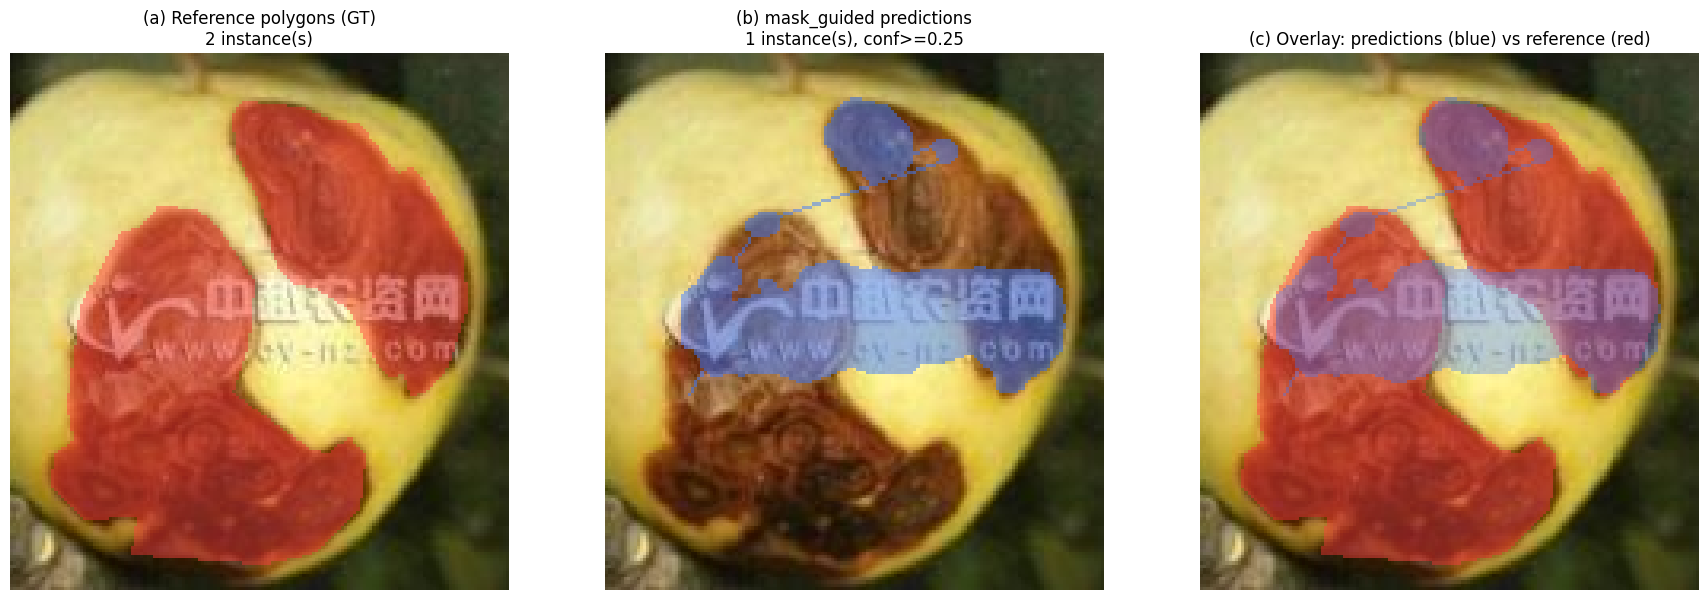

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(crop_gt if not bypassed else crop_rgb)
axes[0].set_title(f"(a) Reference polygons (GT)\n{len(kept_gt)} instance(s)")
v_pred = crop_rgb.copy()
for pm in pred_masks:
    layer = v_pred.copy()
    layer[pm.astype(bool)] = (60, 120, 255)
    v_pred = cv2.addWeighted(layer, 0.5, v_pred, 0.5, 0)
axes[1].imshow(v_pred)
axes[1].set_title(f"(b) mask_guided predictions\n{len(pred_masks)} instance(s), conf>=0.25")
v_over = crop_rgb.copy()
for a, gmc in (keep if not bypassed else []):
    layer = v_over.copy(); layer[gmc] = (255, 60, 60)
    v_over = cv2.addWeighted(layer, 0.45, v_over, 0.55, 0)
for pm in pred_masks:
    layer = v_over.copy(); layer[pm.astype(bool)] = (60, 120, 255)
    v_over = cv2.addWeighted(layer, 0.35, v_over, 0.65, 0)
axes[2].imshow(v_over)
axes[2].set_title("(c) Overlay: predictions (blue) vs reference (red)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("/content/pred_vs_gt.png", dpi=110, bbox_inches="tight")
plt.show()

### Per-instance agreement: predicted masks vs reference polygons

Computes the IoU of every predicted mask against every kept reference polygon mask (both in crop coordinates) and greedily matches each reference instance to its best-overlapping prediction. The small table and CSV export quantify agreement **for this single example only** — they are not the paper's test-set metrics.

日本語: 予測マスクと正解ポリゴンのIoUを計算し、対応表とCSVを出力します（1枚のみの参考値で、論文のテストセット指標ではありません）。

In [ ]:
import pandas as pd

rows = []
if kept_gt and len(pred_masks):
    iou_mat = np.zeros((len(kept_gt), len(pred_masks)))
    for gi, gm in enumerate(kept_gt):
        for pi, pm in enumerate(pred_masks):
            inter = np.logical_and(gm, pm).sum()
            union_px = np.logical_or(gm, pm).sum()
            iou_mat[gi, pi] = inter / union_px if union_px else 0.0
    for gi, a in enumerate(kept_anns):
        pi = int(np.argmax(iou_mat[gi]))
        rows.append({
            "gt_annotation_id": a["id"],
            "gt_class": class_label(a["category_id"]),
            "gt_area_px": int(kept_gt[gi].sum()),
            "best_pred_index": pi,
            "pred_class": names[pred_cls[pi]] if len(pred_cls) else None,
            "pred_conf": float(pred_conf[pi]) if len(pred_conf) else None,
            "iou_best": float(iou_mat[gi, pi]),
        })
df = pd.DataFrame(rows)
if len(df):
    display(df)
    df.to_csv("/content/instance_iou.csv", index=False)
    print(f"mean IoU of best matches: {df['iou_best'].mean():.3f} (n={len(df)} GT instances)")
else:
    print("No GT/prediction pairs to compare on this sample.")
print("saved: /content/instance_iou.csv")

,gt_annotation_id,gt_class,gt_area_px,best_pred_index,pred_class,pred_conf,iou_best
0,1,category_id 0,6686,0,cherry leaf spot,0.398025,0.176081
1,2,category_id 0,3850,0,cherry leaf spot,0.398025,0.276709


mean IoU of best matches: 0.226 (n=2 GT instances)
saved: /content/instance_iou.csv


### Author's published `mask_guided` test metrics (context)

Downloads the authors' own `mask_guided/evaluation_results.json` from the pinned commit and prints it next to the paper's Table 2 row. These are **dataset-level published results**: the single-example IoUs above must not be compared to them directly. Note that the released JSON's test values (Box mAP50 ≈ 0.285, Mask mAP50 ≈ 0.273) **do not match** the paper's Table 2 row (32.69 % / 13.70 %) — an observed discrepancy between the released evaluation record and the manuscript; both are shown as-is.

日本語: 著者公開の評価結果JSONと論文Table 2の行を表示します。両者の数値は一致しない点（公開記録と論文の差異）にも注意してください。上記の1枚のIoUとは直接比較できません。

In [ ]:
EVAL_URL = "https://raw.githubusercontent.com/YouROS12/plantseg-mask-guided/446c9666d21ffe3423a9e37169b49d7f1df49fa9/mask_guided/evaluation_results.json"
EVAL_SIZE, EVAL_SHA = 1117, "5d859a371ec8984e9acc83b6e6e567dc49e06bdb"
raw_eval = urllib.request.urlopen(EVAL_URL, timeout=60).read()
assert len(raw_eval) == EVAL_SIZE, f"size mismatch: {len(raw_eval)}"
assert hashlib.sha1(b"blob %d\0" % len(raw_eval) + raw_eval).hexdigest() == EVAL_SHA, "blob sha mismatch"
Path("/content/evaluation_results.json").write_bytes(raw_eval)
print(json.dumps(json.loads(raw_eval), indent=2))

print("""
Paper Table 2, mask_guided (test, N=1,146): mIoU 33.72% | Box mAP50 32.69% | Box mAP50-95 19.95%
                                           Mask mAP50 13.70% | Mask mAP50-95 5.47%  (oracle condition)""")

{
  "standard_val": {
    "split": "val",
    "box_map50": 0.321784057921307,
    "box_map75": 0.13326224734004571,
    "box_map": 0.1585115330486947,
    "box_precision": 0.3602514062193079,
    "box_recall": 0.40572445605935686,
    "seg_map50": 0.30441808577382223,
    "seg_map75": 0.07595650456593527,
    "seg_map": 0.12421147807359327,
    "seg_precision": 0.36043398855699504,
    "seg_recall": 0.37675020113812796,
    "speed_preprocess": 0.32195737284998743,
    "speed_inference": 10.33126581526999,
    "speed_postprocess": 1.602400161032181
  },
  "standard_test": {
    "split": "test",
    "box_map50": 0.2847482285886449,
    "box_map75": 0.11998375341031849,
    "box_map": 0.1410367117108047,
    "box_precision": 0.3397869139987711,
    "box_recall": 0.33956069338626704,
    "seg_map50": 0.2732972139006149,
    "seg_map75": 0.08169841159084487,
    "seg_map": 0.11950260238754656,
    "seg_precision": 0.3522867974651196,
    "seg_recall": 0.3177349883393261,
    "speed_preproce

## Interpretation and limitations

- **What was verified here**: the released `mask_guided` checkpoint loads and produces instance masks on a PlantSeg test image processed exactly as the paper's Algorithm 1 prescribes (τ = 0.85 bypass, ρ = 0.20 union-box padding, MASK mode); predicted masks are compared to the authors' own reference polygons per instance.
- **Oracle scope**: the crop window came from the evaluated image's ground truth (paper §3.4.1.1). Gains in the paper under this condition are an upper bound, not a deployable pipeline.
- **Not verified here**: the published test-set metrics (mIoU 33.72 %, Box mAP50 32.69 %, Mask mAP50 13.70 %) cover all 1,146 test images with unrecorded evaluation thresholds; this notebook runs one image with ultralytics defaults. A single example cannot confirm dataset-level numbers.
- **Adaptations**: Algorithm 1 is an AI-assisted port (strategy classes unreleased); `min_mask_quality = 0.3` from the released pipeline metadata is not used because it affects annotation extraction, not the deterministic test-time crop; input is passed as a NumPy array instead of the training-time dataloader; predicted masks are rasterized from the ultralytics result's `masks.xy` polygons at crop resolution (the raw `masks.data` grid is at model-input scale).
- **Known paper/artifact discrepancies** (observed during diagnostics, 2026-10-23): the released `mask_guided/args.yaml` records `epochs: 100, patience: 12` while the paper reports 200 epochs / patience 25; the released checkpoint defines **10 classes** while the paper evaluates 115 PlantSeg categories; the released `annotation_test.json` lists 2,295 images (no category-name table) while the paper's test split has 1,146 images; and the released `evaluation_results.json` test values (Box mAP50 0.285, Mask mAP50 0.273) differ from Table 2 (32.69 % / 13.70 %). The authors also flag identical `mask_guided`/`mask_guided_aware` mAcc cells as unverified. None of these prevents running the released checkpoint, but they bound what this demo can claim.

日本語: 公開成果物と論文との間には複数の不整合（エポック数、クラス数10対115、テスト画像数、評価値の差異）が観測されています。いずれも公開チェックポイントの実行は妨げませんが、本デモが主張できる範囲を限定します。

日本語: 本デモで検証したのは、公開チェックポイントがAlgorithm 1どおりのcropに対してインスタンスマスクを生成すること、および正解ポリゴンとのIoU比較です。論文のテストセット全体の指標（Table 2）は本ノートブックでは検証していません。Guided cropは正解依存のオラクル条件である点に留意してください。

## References

1. Natij et al. (2026), Front. Artif. Intell. 9:1835997, DOI 10.3389/frai.2026.1835997 (CC BY 4.0).
2. Code: `github.com/YouROS12/plantseg-mask-guided` @ `446c9666d21ffe3423a9e37169b49d7f1df49fa9` (no license file).
3. Dataset: Wei et al. (2026), PlantSeg, *Scientific Data* 13:205; Zenodo record 14935094 (`plantsegv3.zip`, MD5 9458f4fb…).
4. Ultralytics YOLO11: `github.com/ultralytics/ultralytics` (AGPL-3.0).

### Validation record (post-execution note, 2026-10-23)

This notebook was executed **top to bottom on a fresh Google Colab CPU runtime** (Python 3.13.16, torch 2.11.0+cpu, ultralytics 8.4.184); every cell completed without errors and all saved outputs above were produced by that CPU run (inference ≈ 10.4 s on the 157×169 px guided crop). The released checkpoint was verified against its pinned GitHub blob SHA-1 and the Zenodo archive against its published MD5. A first T4 GPU run the same day completed all cells through inference and the evaluation-record cells but failed in the prediction-mask post-processing (a dtype bug, since fixed); a later T4 allocation was refused by the Colab account session limit, so GPU execution remains supported by the notebook but is not freshly validated here.

日本語: 本ノートブックは新規のColab CPUランタイムで先頭から末尾まで実行され、全セルがエラーなく完了しました（保存済み出力はCPU実行によるものです）。T4 GPUはノートブック自体は対応していますが、今回の検証ではアカウントのセッション上限により割り当てが拒否され、未検証です。
